# Chapter 6 — Harmonic oscillator and coherent states

Ladder operators truncated at $N$ levels, Fock states, then a coherent state $|\alpha\rangle$: Poisson law, $\langle N\rangle=|\alpha|^2$, $\Delta N=|\alpha|$ and motion of $\langle x\rangle$.

*PHY321 Notebook — works offline: numpy and matplotlib are enough.*

In [1]:
import numpy as np
import matplotlib.pyplot as plt
np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(321)  # fixed seed: reproducible results

In [2]:
from math import lgamma
Nmax = 80
a = np.diag(np.sqrt(np.arange(1, Nmax)), 1)                # truncated annihilation operator
ad = a.T
comm = a @ ad - ad @ a
print("[a, a†] = 1 away from the last level:", np.allclose(np.diag(comm)[:-1], 1))
H = ad @ a + 0.5*np.eye(Nmax)                              # in units of ħω
print("energy levels", np.diag(H)[:5])

[a, a†] = 1 away from the last level: True
energy levels [0.5 1.5 2.5 3.5 4.5]


norm = 0.9999999999999999
error on a|α> = α|α>: 1.2773399650228326e-15
<N> = 3.9999999999999987  |α|² = 4.0   ΔN = 2.000000000000001  |α| = 2.0


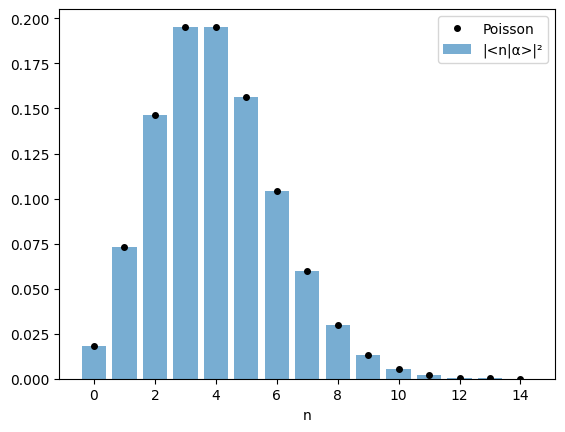

In [3]:
alpha = 2.0
n = np.arange(Nmax)
logc = -abs(alpha)**2/2 + n*np.log(abs(alpha)) - np.array([lgamma(i+1)/2 for i in n])
c = np.exp(logc).astype(complex)                            # coefficients of |α> in the Fock basis
print("norm =", np.linalg.norm(c))
print("error on a|α> = α|α>:", np.linalg.norm(a @ c - alpha*c))
N_op = ad @ a
mN = np.real(c.conj() @ N_op @ c); dN = np.sqrt(np.real(c.conj() @ N_op @ N_op @ c) - mN**2)
print("<N> =", mN, " |α|² =", alpha**2, "  ΔN =", dN, " |α| =", abs(alpha))
from math import factorial
poisson = np.array([np.exp(-alpha**2) * alpha**(2*i) / factorial(i) for i in range(15)])
plt.bar(range(15), np.abs(c[:15])**2, alpha=0.6, label="|<n|α>|²"); plt.plot(range(15), poisson, 'ko', ms=4, label="Poisson")
plt.xlabel('n'); plt.legend(); plt.show()

## Time evolution

With $\hat x=(a+a^\dagger)/\sqrt2$ (units $\sqrt{\hbar/m\omega}$), $\langle x\rangle(t)=\sqrt2\,\alpha\cos\omega t$ for real $\alpha$, with no spreading.

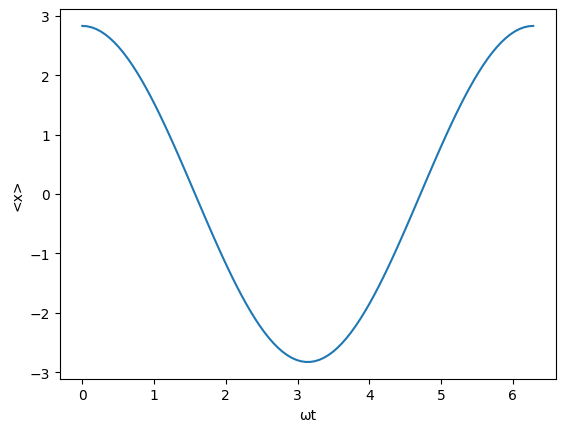

<x>(t) = √2 α cos(ωt) checked


In [4]:
X = (a + ad)/np.sqrt(2)
ts = np.linspace(0, 2*np.pi, 100)
xm = []
for t_ in ts:
    ct = c * np.exp(-1j*(n + 0.5)*t_)
    xm.append(np.real(ct.conj() @ X @ ct))
xm = np.array(xm)
assert np.allclose(xm, np.sqrt(2)*alpha*np.cos(ts), atol=1e-6)
plt.plot(ts, xm); plt.xlabel('ωt'); plt.ylabel('<x>'); plt.show()
print("<x>(t) = √2 α cos(ωt) checked")